# Measuring a Multiport Device with a 2-Port Network Analyzer

## Introduction

In microwave measurements, one commonly needs to measure a n-port device with a m-port network analyzer ($m<n$ of course). 

<img src="nports_with_2ports.svg"/>

This can be done by terminating each non-measured port with a matched load, and assuming the reflected power is negligible. With multiple measurements, it is then possible to reconstitute the original n-port. The first section of this example illustrates this method. 

However, in some cases this may not provide the most accurate results, or even be possible in all measurement environments. Or, sometime it is not possible to have matched loads for all ports. The second part of this example presents an elegant solution to this problem, using impedance renormalization. We'll call it *Tippet's technique*, because it has a good ring to it.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np

import skrf as rf
from skrf.network import connect, subnetwork

%matplotlib inline

rf.stylely()

## Matched Ports
Let's assume that you have a 2-ports VNA. In order to measure a n-port network, you will need at least $p=n(n-1)/2$ measurements between the different pair of ports (total number of unique pairs of a set of n). 

For example, let's assume we wants to measure a 3-ports network with a 2-ports VNA. One needs to perform at least 3 measurements: between ports 1 & 2, between ports 2 & 3 and between ports 1 & 3. We will assume these measurements are then converted into three 2-ports `Network`. To build the full 3-ports `Network`, one needs to provide a list of these 3 (sub)networks to the scikit-rf builtin function `n_twoports_2_nport`. While the order of the measurements in the list is not important, pay attention to define the `Network.name` properties of these subnetworks to contain the port index, for example `p12` for the measurement between ports 1&2 or `p23` between 2&3, etc.

Let's suppose we want to measure a tee:

In [2]:
tee = rf.data.tee
print(tee)

3-Port Network: 'tee',  330.0-500.0 GHz, 201 pts, z0=[50.+0.j 50.+0.j 50.+0.j]


For the sake of the demonstration, we will "fake" the 3 distinct measurements by extracting 3 subsets of the original Network, i.e., 3 subnetworks:

In [3]:
# 2 port Networks as if one measures the tee with a 2 ports VNA
tee12 = subnetwork(tee, [0, 1])  # 2 port Network btw ports 1 & 2, port 3 being matched
tee23 = subnetwork(tee, [1, 2])  # 2 port Network btw ports 2 & 3, port 1 being matched
tee13 = subnetwork(tee, [0, 2])  # 2 port Network btw ports 1 & 3, port 2 being matched

In reality of course, these three Networks comes from three measurements with distinct pair of ports, the non-used port being properly matched. 

Before using the `n_twoports_2_nport` function, one must define the name of these subsets by setting the `Network.name` property, in order the function to know which corresponds to what:

In [4]:
tee12.name = 'tee12'
tee23.name = 'tee23'
tee13.name = 'tee13'

Now we can build the 3-ports Network from these three 2-port subnetworks:

In [5]:
ntw_list = [tee12, tee23, tee13]
tee_rebuilt = rf.network.n_twoports_2_nport(ntw_list, nports=3)
print(tee_rebuilt)

3-Port Network: '',  330.0-500.0 GHz, 201 pts, z0=[50.+0.j 50.+0.j 50.+0.j]


In [6]:
# this is an ideal example, both Network are thus identical
print(tee == tee_rebuilt)

True


## Tippet's Technique 
This example demonstrates a numerical test of the technique described in "*A Rigorous Technique for Measuring the Scattering Matrix of a Multiport Device with a 2-Port Network Analyzer*" [1].

In *Tippets technique*, several sub-networks are measured in a similar way as before, but the port terminations are not assumed to be matched. Instead, the terminations just have to be known and no more than one can be completely reflective. So, in general $|\Gamma| \ne 1$. 

During measurements, each port is terminated with a consistent termination. So port 1 is always terminated with $Z_1$ when not being measured. Once measured, each sub-network is re-normalized to these port impedances. Think about that. Finally, the composite network is constructed, and  may then be re-normalized to the desired system impedance, say $50$ ohm. 

* [1] J. C. Tippet and R. A. Speciale, “A Rigorous Technique for Measuring the Scattering Matrix of a Multiport Device with a 2-Port Network Analyzer,” IEEE Transactions on Microwave Theory and Techniques, vol. 30, no. 5, pp. 661–666, May 1982.

## Outline of Tippet's Technique

Following the example given in [1], measuring a 4-port network with a 2-port network analyzer.

An outline of the technique: 

1. Calibrate 2-port network analyzer
2. Get four known terminations ($Z_1, Z_2, Z_3,Z_4$). No more than one can have  $|\Gamma| = 1$
3. Measure all combinations of 2-port subnetworks (there are 6). Each port not currently being measured must be terminated with its corresponding load.
4. Renormalize each subnetwork to the impedances of the loads used to terminate it when note being measured. 
5. Build composite 4-port, renormalize to VNA impedance. 

## Implementation

First, we create a Media object, which is used to generate networks for testing. We will use WR-10 Rectangular waveguide.

In [7]:
wg = rf.instances.wr10

Next, lets generate a random 4-port network which will be the DUT, that we are trying to measure with out 2-port network analyzer. 

In [8]:
dut = wg.random(n_ports  = 4,name= 'dut')
dut

4-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j 50.+0.j 50.+0.j 50.+0.j]

Now, we need to define the loads used to terminate each port when it is not being measured, note as described in [1] not more than one can be have full reflection, $|\Gamma| = 1$

In [9]:
loads = [wg.load(.1+.1j),
         wg.load(.2-.2j),
         wg.load(.3+.3j),
         wg.load(.5),
         ]
# construct the impedance array, of shape FXN
z_loads = np.array([k.z.flatten() for k in loads]).T


Create required measurement port combinations.  There are 6 different measurements required to measure a 4-port with a 2-port VNA.  In general, #measurements = $n\choose 2$, for n-port DUT on  a 2-port VNA.

In [10]:
ports = np.arange(dut.nports)
port_combos = list(combinations(ports, 2))
port_combos

[(np.int64(0), np.int64(1)),
 (np.int64(0), np.int64(2)),
 (np.int64(0), np.int64(3)),
 (np.int64(1), np.int64(2)),
 (np.int64(1), np.int64(3)),
 (np.int64(2), np.int64(3))]

Now to do it. Ok we loop over the port combo's and connect the loads to the right places, simulating  actual measurements. Each raw subnetwork measurement is saved, along with the renormalized subnetwork.   Finally, we stuff the result into the 4-port composite network. 

In [11]:
composite = wg.match(nports = 4)  # composite network, to be filled.
measured,measured_renorm = {},{}  # measured subnetworks and renormalized sub-networks

# ports  `a` and `b` are the ports we will connect the VNA too
for a,b in port_combos:
    # port `c` and `d` are the ports which we will connect the loads too
    c,d =ports[(ports!=a)& (ports!=b)]

    # determine where `d` will be on four_port, after its reduced to a three_port
    e = np.where(ports[ports!=c]==d)[0][0]

    # connect loads
    three_port = connect(dut,c, loads[c],0)
    two_port =  connect(three_port,e, loads[d],0)

    # save raw and renormalized 2-port subnetworks
    measured['%i%i'%(a,b)] = two_port.copy()
    two_port.renormalize(np.c_[z_loads[:,a],z_loads[:,b]])
    measured_renorm['%i%i'%(a,b)] = two_port.copy()

    # stuff this 2-port into the composite 4-port
    for i,m in enumerate([a,b]):
        for j,n in enumerate([a,b]):
            composite.s[:,m,n] = two_port.s[:,i,j]

    # properly copy the port impedances
    composite.z0[:,a] = two_port.z0[:,0]
    composite.z0[:,b] = two_port.z0[:,1]

# finally renormalize from load z0 to 50 ohms
composite.renormalize(50)

## Results

### Self-Consistency

Note that 6-measurements of 2-port subnetworks works out to 24 s-parameters, and we only need 16. This is because each reflect, s-parameter is measured three-times. As, in [1], we will use this redundant measurement as a check of our accuracy.

The renormalized networks are stored in a dictionary with names based on their port indices, from this you can see that each have been renormalized to the appropriate z0. 

In [12]:
measured_renorm

{'01': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[59.75609756+12.19512195j 67.64705882-29.41176471j],
 '02': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[59.75609756+12.19512195j 70.68965517+51.72413793j],
 '03': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[ 59.75609756+12.19512195j 150.         +0.j        ],
 '12': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[67.64705882-29.41176471j 70.68965517+51.72413793j],
 '13': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[ 67.64705882-29.41176471j 150.         +0.j        ],
 '23': 2-Port Network: 'dut',  75.0-110.0 GHz, 1001 pts, z0=[ 70.68965517+51.72413793j 150.         +0.j        ]}

Plotting all three raw measurements of $S_{11}$, we can see that they are not in agreement. These plots answer to plots 5 and 7 of [1]

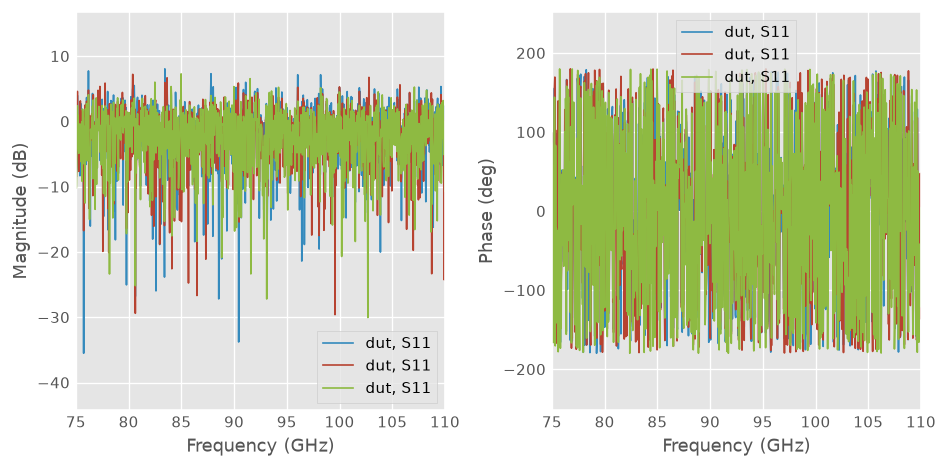

In [13]:
s11_set = rf.networkSet.NetworkSet([measured[k] for k in measured if k[0]=='0'])

plt.figure(figsize = (8,4))
plt.subplot(121)
s11_set .plot_s_db(0,0)
plt.subplot(122)
s11_set .plot_s_deg(0,0)
plt.tight_layout()

However, the renormalized measurements agree perfectly. These plots answer to plots 6 and 8 of [1]

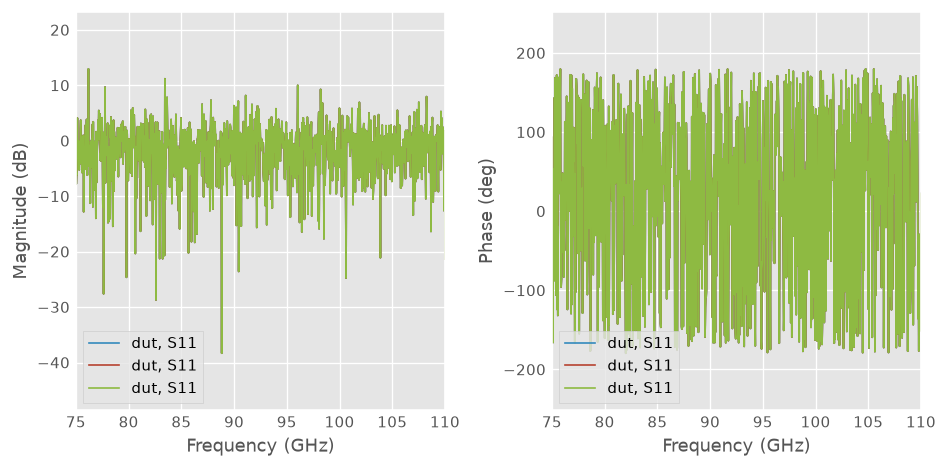

In [14]:
s11_set = rf.networkSet.NetworkSet([measured_renorm[k] for k in measured_renorm if k[0]=='0'])

plt.figure(figsize = (8,4))
plt.subplot(121)
s11_set .plot_s_db(0,0)
plt.subplot(122)
s11_set .plot_s_deg(0,0)
plt.tight_layout()

### Test For Accuracy

Making sure our composite network is the same as our DUT

In [15]:
composite == dut

True

Nice!. How close ?

In [16]:
sum((composite - dut).s_mag)

array([[5.75432710e-13, 5.57038022e-13, 5.47595937e-13, 5.22862112e-13],
       [5.68207409e-13, 5.77168444e-13, 5.27149308e-13, 5.15842564e-13],
       [5.41462741e-13, 5.65757524e-13, 5.24828522e-13, 5.02727003e-13],
       [5.41858521e-13, 5.36122502e-13, 5.21681944e-13, 5.44314183e-13]])

Dang!

## Practical Application

This could be used in many ways. In waveguide, one could just make a measurement of a radiating open after a standard two-port calibration (like TRL). Then using *Tippets technique*, you can  leave each port wide open while not being measured. This way you dont have to buy a bunch of loads. How sweet would that be?



## More Complex Simulations

In [17]:
def tippits(dut, gamma, noise=None):
    """simulate tippits technique on a 4-port dut.
    """
    ports = np.arange(dut.nports)
    port_combos = list(combinations(ports, 2))

    loads = [wg.load(gamma) for k in ports]

    # construct the impedance array, of shape FXN
    z_loads = np.array([k.z.flatten() for k in loads]).T
    composite = wg.match(nports = dut.nports)  # composite network, to be filled.

    # ports  `a` and `b` are the ports we will connect the VNA too
    for a,b in port_combos:
        # port `c` and `d` are the ports which we will connect the loads too
        c,d =ports[(ports!=a)& (ports!=b)]

        # determine where `d` will be on four_port, after its reduced to a three_port
        e = np.where(ports[ports!=c]==d)[0][0]

        # connect loads
        three_port = connect(dut,c, loads[c],0)
        two_port =  connect(three_port,e, loads[d],0)

        if noise is not None:
            two_port.add_noise_polar(*noise)
        # save raw and renormalized 2-port subnetworks
        measured['%i%i'%(a,b)] = two_port.copy()
        two_port.renormalize(np.c_[z_loads[:,a],z_loads[:,b]])
        measured_renorm['%i%i'%(a,b)] = two_port.copy()

        # stuff this 2-port into the composite 4-port
        for i,m in enumerate([a,b]):
            for j,n in enumerate([a,b]):
                composite.s[:,m,n] = two_port.s[:,i,j]

        # properly copy the port impedances
        composite.z0[:,a] = two_port.z0[:,0]
        composite.z0[:,b] = two_port.z0[:,1]

    # finally renormalize from load z0 to 50 ohms
    composite.renormalize(50)

    return composite

Text(0, 0.5, "Max Error in DUT's dB(S)")

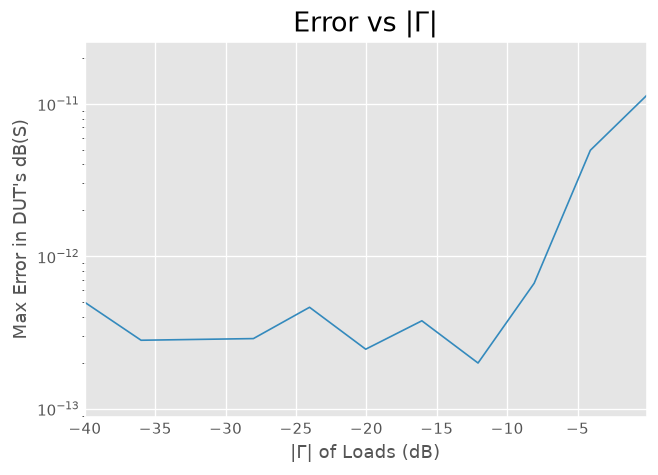

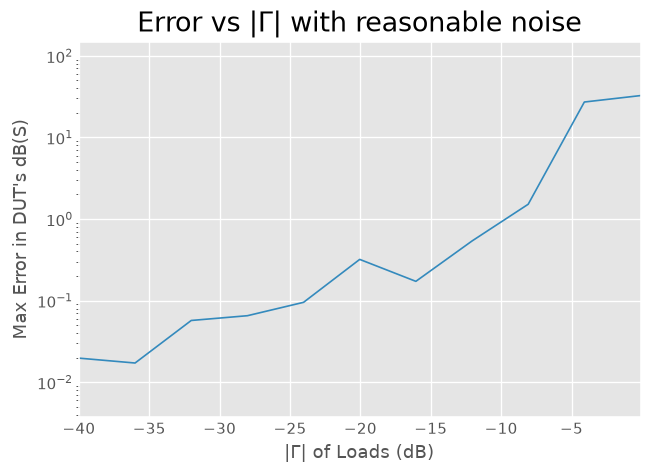

In [18]:
dut = wg.random(4)

def er(gamma, *args):
    return max(abs(tippits(dut, rf.mathFunctions.db_2_mag(gamma),*args).s_db-dut.s_db).flatten())

gammas = np.linspace(-40,-0.1,11)

plt.title(r'Error vs $|\Gamma|$')
plt.plot(gammas, [er(k) for k in gammas])
plt.semilogy()
plt.xlabel(r'$|\Gamma|$ of Loads (dB)')
plt.ylabel('Max Error in DUT\'s dB(S)')

plt.figure()
noise = (1e-5,.1)
plt.title(r'Error vs $|\Gamma|$ with reasonable noise')
plt.plot(gammas, [er(k, noise) for k in gammas])
plt.semilogy()
plt.xlabel(r'$|\Gamma|$ of Loads (dB)')

plt.ylabel('Max Error in DUT\'s dB(S)')